# Predicting when an engine needs maintenance
### NASA C-MAPSS · Applied machine learning

**TCN ensemble: 20.09 test RMSE, 11.2% below XGBoost.** Calibrated recall is **94.3% vs 93.7%**, with **6 vs 12 false alerts**. The recall advantage remains uncertain.

709 training engines; 707 test engines; uncapped evaluation labels. The official test was previously examined—this is follow-up simulation evidence, not a new blind audit.

Sections 3–11: XGBoost study. Section 12: development comparisons. Section 13: full-data TCN.


In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
ROOT=Path.cwd()
if not (ROOT/'outputs/experiments/results.json').exists(): ROOT=ROOT/'nasa-rul'
sys.path.insert(0,str(ROOT/'scripts'))
EXP=ROOT/'outputs/experiments'
ROB=ROOT/'outputs/robustness'
OUT=ROOT/'outputs/presentation'
r=json.loads((EXP/'results.json').read_text())
metrics=pd.read_csv(EXP/'test_metrics.csv')
comparison=pd.read_csv(EXP/'experiment_comparison.csv')
audit=pd.read_csv(EXP/'audit_metrics.csv')
sensor_audit=pd.read_csv(OUT/'sensor_audit.csv')
sensor_results=json.loads((OUT/'sensor_results.json').read_text())
plt.rcParams.update({'figure.figsize':(10,4.8),'font.size':12,'axes.titlesize':15,
                     'axes.spines.top':False,'axes.spines.right':False,
                     'axes.labelcolor':'#25344a','text.color':'#172b4d'})
COLORS={'Original XGBoost':'#637b96','Random Forest':'#9aabc0','Final XGBoost':'#087f8c'}

## 1. The decision: inspect now, or keep operating?

Predict remaining useful life (RUL), then flag impending failures: **actual RUL ≤30 cycles**. Evaluate prediction error, missed events and false alerts. Inspection costs and real-fleet reliability are not established.


## 2. The evidence: four datasets, all available engines

Each cycle records three operating settings and 21 sensors. Training histories reach failure; test histories are truncated. Dataset + engine ID identifies each history.


In [2]:
data=pd.read_csv(EXP/'data_audit.csv')
table=data.pivot(index='dataset',columns='split',values='engines').reindex(['FD001','FD002','FD003','FD004'])
table=table.rename(columns={'train':'Training engines','test':'Test engines'})
table['Operating conditions']=[1,6,1,6]
table['Fault modes']=[1,1,2,2]
display(table[['Training engines','Test engines','Operating conditions','Fault modes']].rename_axis(index=None,columns=None))

,Training engines,Test engines,Operating conditions,Fault modes
FD001,100,100,1,1
FD002,260,259,6,1
FD003,100,100,1,2
FD004,249,248,6,2


**160,359 training rows; 104,897 test rows.** Hashes, engine/cycle keys and finite values checked. FD004 contains 249 training / 248 test engines; the bundled README reverses these counts. Sensor extremes are retained.

Source: [NASA archive manifest](data/source.json). Simulated trajectories, not real-fleet validation.


## 3. A fair comparison: keep engines separate

**567 development engines → three-fold CV → freeze model/threshold → 142-engine audit → refit all 709 → 707-engine test.** This describes the original XGBoost study.

Three equally weighted endpoints per engine: primary RUL 1–200 with ≥20 observed cycles; broad endpoints span earlier life. Fold-only preprocessing and causal features prevent leakage. The planning window is assumed; prior test results motivated the study.


## 4. Are all 21 sensors useful?

**Retain 17 sensors.** Variance filtering removes **1, 5, 18, 19** and their history features. XGBoost uses 127 inputs: 119 sensor-derived features plus cycle, settings and dataset indicators.

Sensors **6, 10, 16** vary in some datasets; test their removal rather than assume they are useless.


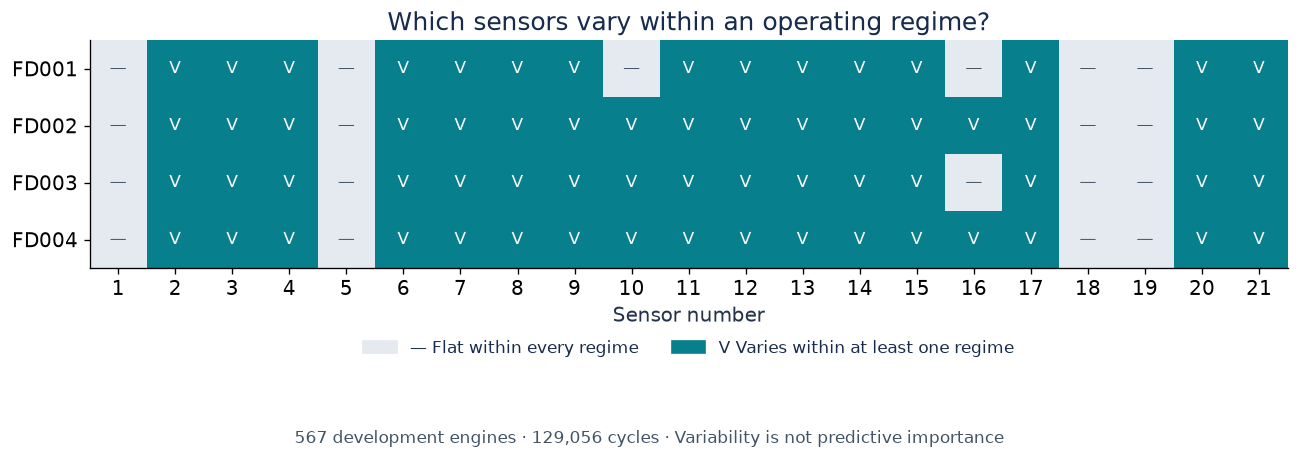

In [3]:
order=[f'sensor_{i}' for i in range(1,22)]
sensor_variation=pd.read_csv(OUT/'sensor_variation_development.csv')
variation=sensor_variation.pivot(index='dataset',columns='sensor',values='varies_within_regime')[order]
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
fig,ax=plt.subplots(figsize=(11,3.5))
ax.imshow(variation.to_numpy(dtype=int),cmap=ListedColormap(['#e5eaf0','#087f8c']),vmin=0,vmax=1,aspect='auto')
for i in range(4):
    for j in range(21):
        ax.text(j,i,'V' if variation.iloc[i,j] else '—',ha='center',va='center',
                color='white' if variation.iloc[i,j] else '#425466',fontsize=10)
ax.set(xticks=np.arange(21),xticklabels=np.arange(1,22),yticks=np.arange(4),yticklabels=variation.index,
       xlabel='Sensor number',title='Which sensors vary within an operating regime?')
ax.legend(handles=[Patch(color='#e5eaf0',label='— Flat within every regime'),Patch(color='#087f8c',label='V Varies within at least one regime')],
          loc='upper center',bbox_to_anchor=(.5,-.25),ncol=2,frameon=False,fontsize=10)
fig.tight_layout()
fig.text(.5,-.08,'567 development engines · 129,056 cycles · Variability is not predictive importance',
         ha='center',fontsize=10,color='#425466')
fig.savefig(OUT/'sensor_variation.png',dpi=160,bbox_inches='tight')
plt.show()


Development engines only (567). “Varies” means ≥2 distinct readings within a dataset/regime; “flat” means constant. **1, 5, 18, 19** are flat throughout; **6, 10, 16** are not. Variation alone does not establish predictive value.


### Correlation shows overlap, not a removal rule

Correlations compare regime-normalized sensor readings. Confusion matrices evaluate predictions; they cannot identify useless sensors.


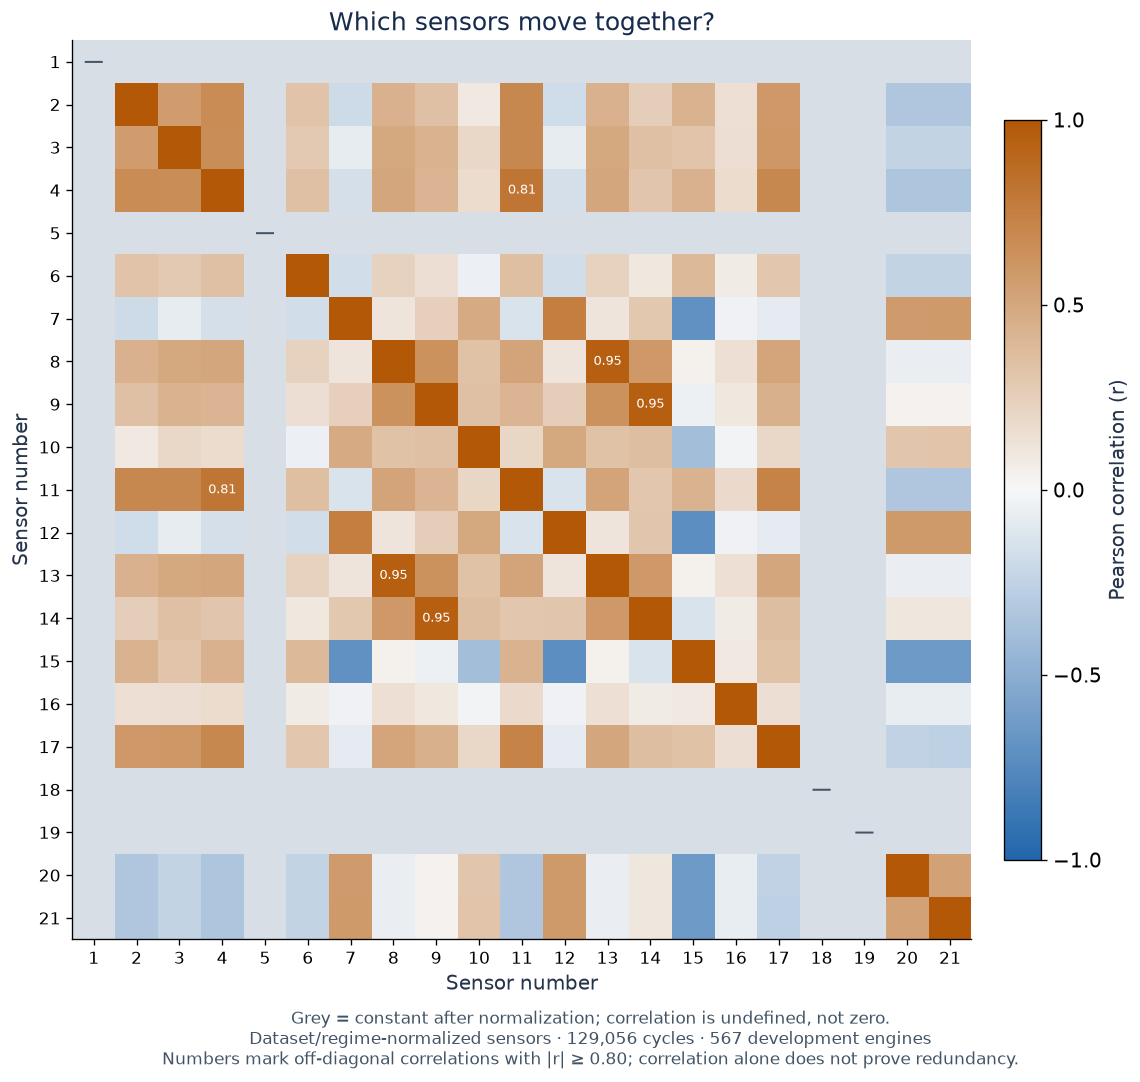

In [4]:
corr=pd.read_csv(OUT/'sensor_correlation.csv',index_col='sensor').loc[order,order]
meta=json.loads((OUT/'sensor_visual_metadata.json').read_text())
from matplotlib.colors import LinearSegmentedColormap
palette=LinearSegmentedColormap.from_list('sensor_signed',['#2166ac','#f7f7f7','#b35806'])
palette.set_bad('#d8dee5')
fig,ax=plt.subplots(figsize=(10,9))
values=corr.to_numpy()
im=ax.imshow(np.ma.masked_invalid(values),vmin=-1,vmax=1,cmap=palette,interpolation='nearest')
labels=[str(i) for i in range(1,22)]
ax.set(xticks=np.arange(21),yticks=np.arange(21),xticklabels=labels,yticklabels=labels,
       xlabel='Sensor number',ylabel='Sensor number',title='Which sensors move together?')
ax.tick_params(labelsize=10)
for i in range(21):
    for j in range(21):
        value=values[i,j]
        if i!=j and np.isfinite(value) and abs(value)>=.80:
            ax.text(j,i,f'{value:.2f}',ha='center',va='center',fontsize=8,color='white')
        elif i==j and not np.isfinite(value):
            ax.text(j,i,'—',ha='center',va='center',fontsize=12,color='#425466')
bar=fig.colorbar(im,ax=ax,shrink=.82,pad=.03,ticks=[-1,-.5,0,.5,1])
bar.set_label('Pearson correlation (r)')
fig.text(.5,.025,'Grey = constant after normalization; correlation is undefined, not zero.\n'
         f"Dataset/regime-normalized sensors · {meta['rows']:,} cycles · {meta['engines']} development engines\n"
         'Numbers mark off-diagonal correlations with |r| ≥ 0.80; correlation alone does not prove redundancy.',
         ha='center',va='bottom',fontsize=10,color='#425466')
fig.tight_layout(rect=(0,.105,1,1))
fig.savefig(OUT/'sensor_correlation.png',dpi=160,bbox_inches='tight')
plt.show()


Strong overlap: **9/14: r=0.949; 8/13: r=0.946**. Correlation suggests ablations, not automatic removal. Grey cells are undefined correlations for constant channels.

Each engine-cycle has equal weight, so longer histories contribute more. These pooled relationships are not model importance or independent observations.


In [5]:
sensor_comparison=pd.read_csv(OUT/'sensor_ablation.csv')
display(sensor_comparison.pivot(index='model',columns='protocol',values='RMSE')
        .rename(columns={'primary':'Primary CV RMSE','broad':'Broad CV RMSE'}).rename_axis(index=None,columns=None).round(3))

,Broad CV RMSE,Primary CV RMSE
Current model: 17 retained sensors,45.317,25.932
Reduced model: 14 sensors,45.216,25.958


**Keep 17 sensors:** primary CV RMSE **25.932**, versus **25.958** after also dropping 6, 10, 16. The tiny difference reverses on broad validation; neither set has an established advantage. Same development engines/endpoints; no test-based selection.


## 5. What changed in the winning pipeline?

1. Fit operating-regime normalization on training engines.
2. Add causal means, variability, slopes, exponential means and changes.
3. Cap training RUL at **150**; score uncapped labels.
4. Fit XGBoost: **depth 6, 800 trees, learning rate 0.03**.

The bounded 21-configuration study also tested weighting, separate models, cycle removal and asymmetric loss. None won the declared CV criterion.


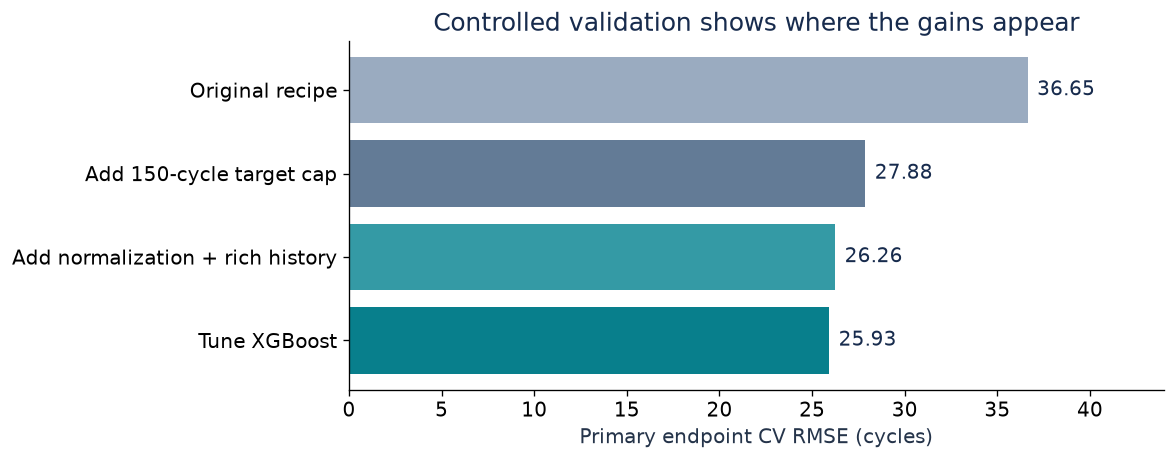

In [6]:
chosen=['reference_raw_uncapped','raw_cap150','rich_cap150','tuned_d6_n800']
labels=['Original recipe','Add 150-cycle target cap','Add normalization + rich history','Tune XGBoost']
primary=comparison[comparison.protocol.eq('primary')].set_index('candidate')
values=primary.loc[chosen,'RMSE'].to_numpy()
fig,ax=plt.subplots(figsize=(10,4))
ax.barh(labels,values,color=['#9aabc0','#637b96','#349aa5','#087f8c'])
ax.invert_yaxis()
ax.set(xlabel='Primary endpoint CV RMSE (cycles)',title='Controlled validation shows where the gains appear',xlim=(0,max(values)*1.2))
for i,v in enumerate(values): ax.text(v+.5,i,f'{v:.2f}',va='center')
fig.tight_layout()
plt.show()

Same development endpoints throughout. These bars summarize combined changes, not isolated causal contributions. Full comparisons: [experiments.ipynb](experiments.ipynb).


## 6. Final XGBoost test result

**RMSE: 33.14 → 22.63 cycles (−31.7%).** MAE: 23.26 → 16.23; bias: +11.94 → +0.31. Same 707 endpoints and uncapped labels.


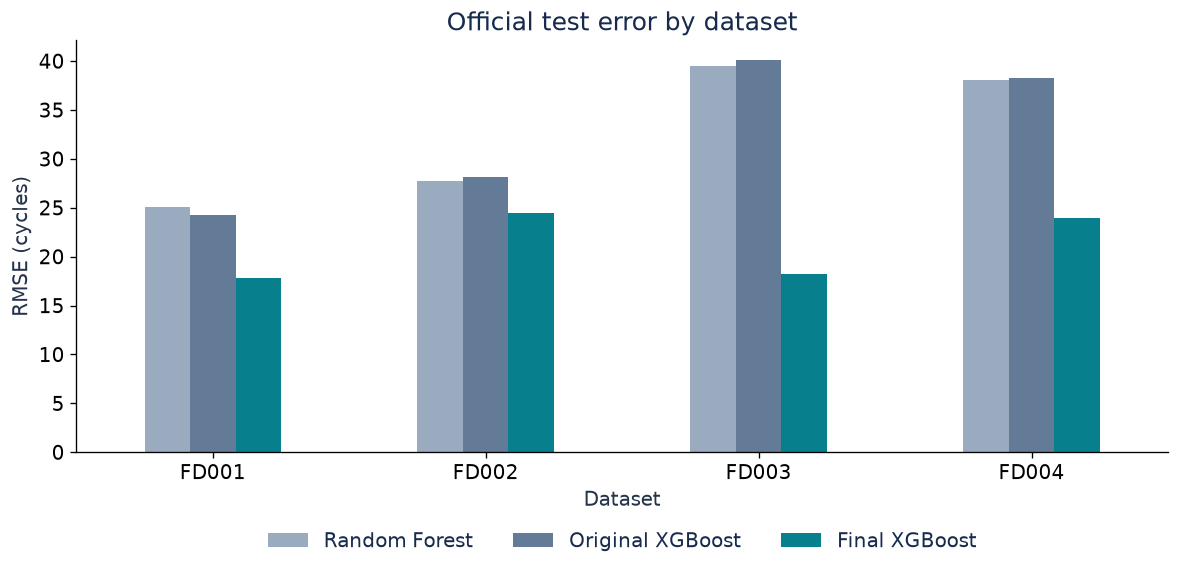

,Random Forest,Original XGBoost,Final XGBoost
FD001,25.06,24.28,17.84
FD002,27.71,28.19,24.47
FD003,39.54,40.11,18.28
FD004,38.02,38.30,23.91


In [7]:
fixed=metrics[metrics.threshold.eq(30)]
selected=fixed[fixed.model.eq('selected') & fixed.dataset.eq('ALL')].iloc[0]
prior=fixed[fixed.model.eq('Random forest') & fixed.dataset.eq('ALL')].iloc[0]
assert np.isclose(selected.RMSE,22.6336838386522)
assert np.isclose(prior.RMSE,33.143425)
lookup={'Random forest':'Random Forest','XGBoost':'Original XGBoost','selected':'Final XGBoost'}
chart=fixed[fixed.dataset.ne('ALL') & fixed.model.isin(lookup)].copy()
chart['Model']=chart.model.map(lookup)
chart=chart.pivot(index='dataset',columns='Model',values='RMSE')[['Random Forest','Original XGBoost','Final XGBoost']]
ax=chart.plot.bar(rot=0,color=[COLORS[c] for c in chart],figsize=(10,5))
ax.set(xlabel='Dataset',ylabel='RMSE (cycles)',title='Official test error by dataset')
ax.legend(title=None,loc='upper center',bbox_to_anchor=(.5,-.15),ncol=3,frameon=False)
plt.tight_layout()
plt.gcf().savefig(OUT/'test_rmse_by_dataset.png',dpi=120,bbox_inches='tight')
plt.show()
display(chart.rename_axis(index=None,columns=None).round(2))

Every subset improves; FD003 improves most. Errors cluster by operating conditions: FD001/FD003 **17.84/18.28**, FD002/FD004 **24.47/23.91**. This is descriptive, not evidence of any single feature's contribution.


## 7. XGBoost maintenance alerts

Development OOF predictions select threshold **34.44** to target ≥90% recall for actual RUL ≤30. On test: **149/159 caught; 12 false alerts**. Calibration changes the alert rule, not RMSE.


In [8]:
alerts=metrics[metrics.model.isin(['XGBoost','selected']) & metrics.dataset.eq('ALL')].copy()
alerts['Model']=alerts.model.map({'XGBoost':'Original XGBoost','selected':'Final XGBoost'})
alerts=alerts.sort_values(['model','threshold'])
view=alerts[['Model','threshold','precision','recall','TP','FN','FP']].rename(columns={
 'threshold':'Alert threshold','precision':'Precision','recall':'Recall','TP':'Caught','FN':'Missed','FP':'False alerts'})
view['Precision']=view.Precision.map(lambda x:f'{x:.1%}')
view['Recall']=view.Recall.map(lambda x:f'{x:.1%}')
view['Alert threshold']=view['Alert threshold'].round(2)
display(view.set_index('Model').rename_axis(index=None,columns=None))

,Alert threshold,Precision,Recall,Caught,Missed,False alerts
Original XGBoost,30.00,94.9%,81.8%,130,29,7
Final XGBoost,30.00,94.7%,89.9%,143,16,8
Final XGBoost,34.44,92.5%,93.7%,149,10,12


Threshold 30 catches 143 engines with 8 false alerts. Calibration catches **6 more**, adding **4 false alerts**. Recall is 90% on audit-primary and 93.7% on test—not a guarantee for another fleet.

NASA's asymmetric score penalizes late predictions more; it does not represent inspection costs.


## 8. The result has a boundary

Original 142-engine audit: primary RMSE **33.01 → 25.67**, improvement 95% interval **4.34–10.59 cycles**.

**Broad early-life RMSE worsens: 39.80 → 43.32.** The training cap limits long-horizon usefulness.


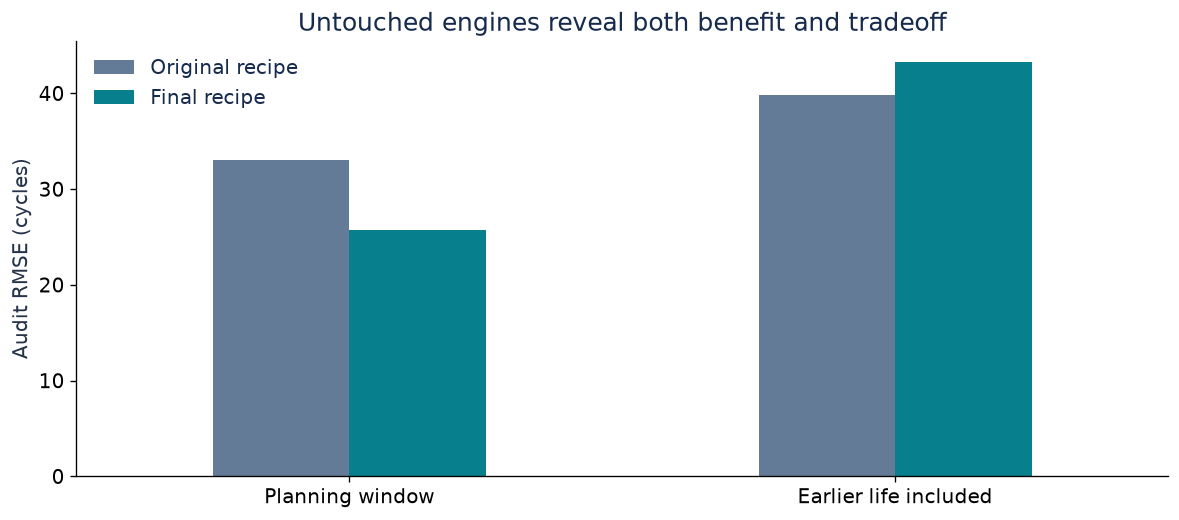

In [9]:
shown=audit[audit.threshold.eq(30)].pivot(index='protocol',columns='model',values='RMSE')
shown=shown.reindex(['primary','broad']).rename(index={'primary':'Planning window','broad':'Earlier life included'},columns={'reference':'Original recipe','selected':'Final recipe'})
ax=shown.plot.bar(rot=0,color=['#637b96','#087f8c'],figsize=(10,4.5))
ax.set(xlabel='',ylabel='Audit RMSE (cycles)',title='Untouched engines reveal both benefit and tradeoff')
ax.legend(title=None,frameon=False)
plt.tight_layout()
plt.show()

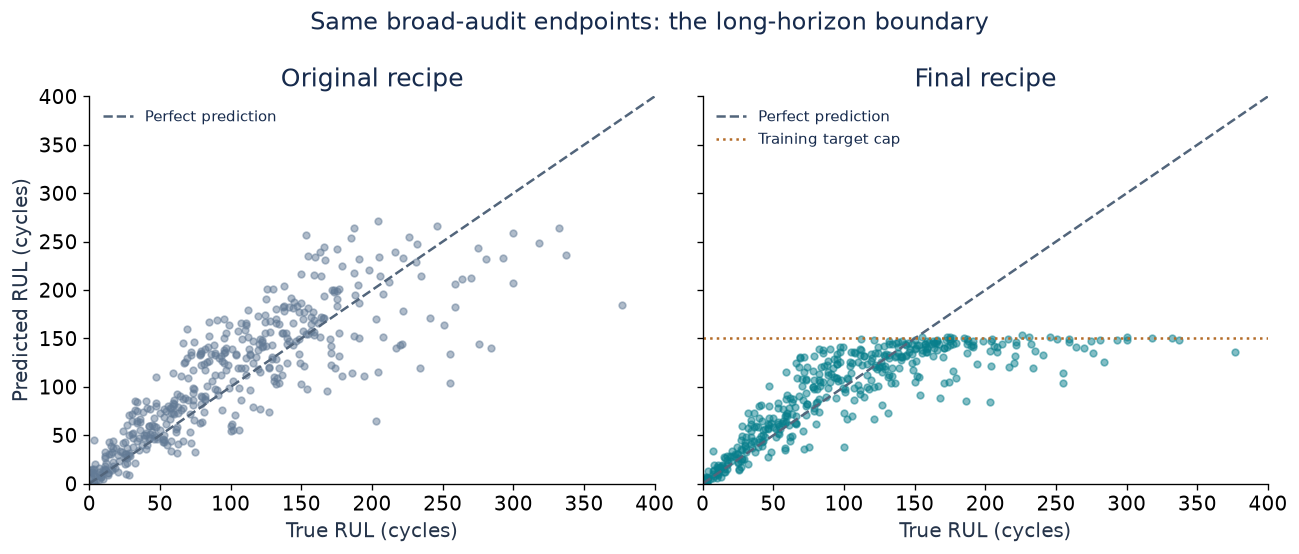

In [10]:
pred=pd.read_csv(EXP/'audit_predictions.csv')
broad=pred[pred.protocol.eq('broad')]
fig,axes=plt.subplots(1,2,figsize=(11,4.7),sharex=True,sharey=True)
limit=np.ceil(max(broad.actual_RUL.max(),broad.predicted_RUL.max())/50)*50
for ax,model,label,color in zip(axes,['reference','selected'],['Original recipe','Final recipe'],['#637b96','#087f8c']):
    points=broad[broad.model.eq(model)]
    ax.scatter(points.actual_RUL,points.predicted_RUL,s=16,alpha=.5,color=color)
    ax.plot([0,limit],[0,limit],color='#52657b',linestyle='--',label='Perfect prediction')
    if model=='selected': ax.axhline(150,color='#b46c29',linestyle=':',label='Training target cap')
    ax.set(xlim=(0,limit),ylim=(0,limit),xlabel='True RUL (cycles)',title=label)
    ax.legend(fontsize=9,frameon=False)
axes[0].set_ylabel('Predicted RUL (cycles)')
fig.suptitle('Same broad-audit endpoints: the long-horizon boundary')
fig.tight_layout()
plt.show()

The dotted line is the training cap, not a hard prediction limit. Both panels use 426 endpoints from the original audit.

## 9. Does the gain survive different splits and windows?

Five splits, each with 567 fitting / 142 held-out engines; three endpoints per engine. Recipes and thresholds stay fixed.

All five improve in 100–250-cycle windows; broad error worsens in four. At 200 cycles, RMSE improves **8.31–12.14 cycles**. Splits overlap and reuse studied engines: sensitivity checks, not independent blind replications.


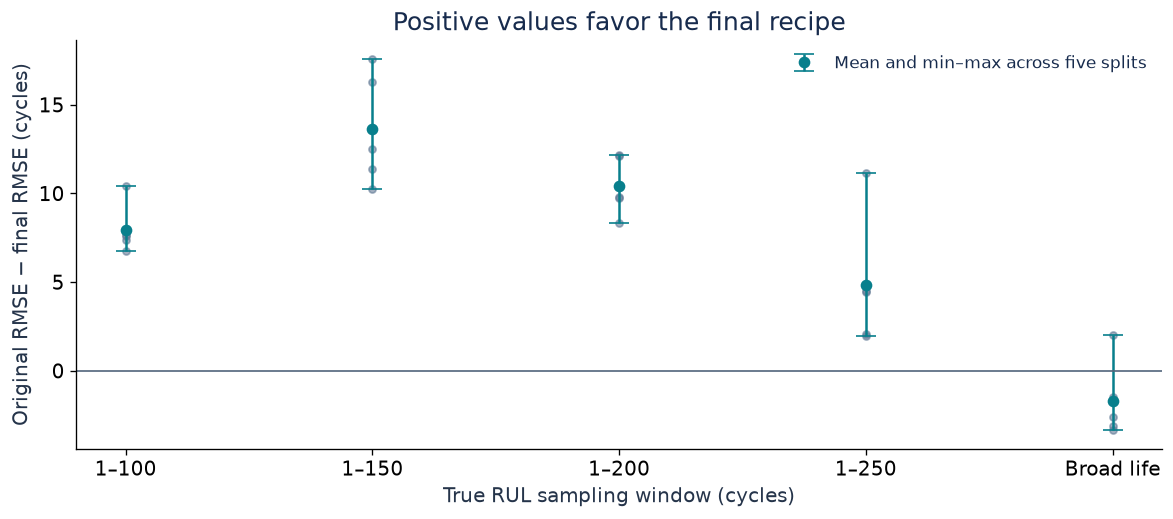

In [11]:
checks=pd.read_csv(ROB/'split_metrics.csv')
gains=checks.pivot(index=['seed','scenario'],columns='model',values='RMSE')
gains['gain']=gains['Original recipe']-gains['Final recipe']
order=['RUL_1_100','RUL_1_150','RUL_1_200','RUL_1_250','broad']
summary=gains.groupby('scenario')['gain'].agg(['min','mean','max']).reindex(order)
fig,ax=plt.subplots(figsize=(10,4.5))
x=np.arange(len(order))
ax.errorbar(x,summary['mean'],yerr=[summary['mean']-summary['min'],summary['max']-summary['mean']],fmt='o',capsize=6,color='#087f8c',label='Mean and min–max across five splits')
for seed,group in gains.reset_index().groupby('seed'):
    ax.scatter(x,group.set_index('scenario').loc[order,'gain'],s=18,color='#637b96',alpha=.6)
ax.axhline(0,color='#52657b',linewidth=1)
ax.set(xticks=x,xticklabels=['1–100','1–150','1–200','1–250','Broad life'],xlabel='True RUL sampling window (cycles)',ylabel='Original RMSE − final RMSE (cycles)',title='Positive values favor the final recipe')
ax.legend(frameon=False,fontsize=10)
fig.tight_layout()
plt.show()

Bars show ranges across splits, not confidence intervals. Broad endpoints sample observation cycles across life.

## 10. How uncertain are the alert results?

95% Wilson intervals on the 707 test endpoints, conditional on fixed models/rules. They exclude selection, refitting and fleet changes.


In [12]:
intervals=pd.read_csv(ROB/'test_alert_intervals.csv')
shown=intervals[intervals.dataset.eq('ALL')].copy()
shown['Estimate [95% interval]']=shown.apply(lambda row:f'{row.estimate:.1%} [{row.lower95:.1%}, {row.upper95:.1%}]',axis=1)
shown['Policy']=shown.model+' / '+shown.threshold.map(lambda value:f'{value:.2f}')
display(shown.pivot(index='Policy',columns='metric',values='Estimate [95% interval]').rename_axis(index=None,columns=None))

,precision,recall
"Final, calibrated alert / 34.44","92.5% [87.4%, 95.7%]","93.7% [88.8%, 96.5%]"
"Final, fixed alert / 30.00","94.7% [89.9%, 97.3%]","89.9% [84.3%, 93.7%]"
Original XGBoost / 30.00,"94.9% [89.8%, 97.5%]","81.8% [75.0%, 87.0%]"


XGBoost calibrated test recall: **93.7% [88.8%, 96.5%]**; precision: **92.5% [87.4%, 95.7%]**. A ≥90% recall guarantee is unsupported. Audit intervals use a separate engine-bootstrap population; see [methods](outputs/robustness/METHODS.md).

## 11. When does the first alert arrive?

Replay held-out histories from cycle 20 until just before failure across the five splits. This evaluates first-alert timing, not one-endpoint recall.


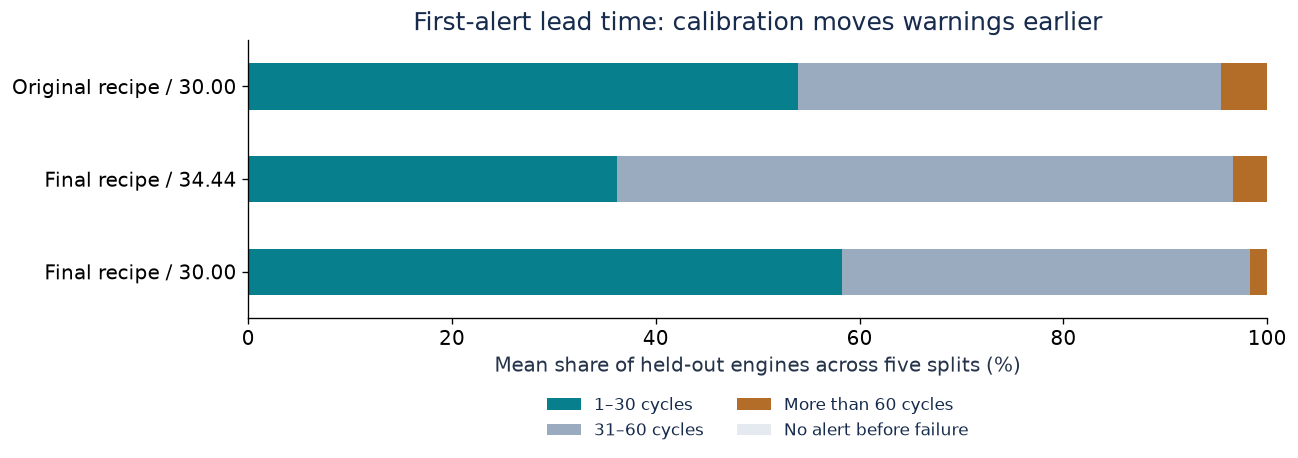

,Minimum split median (cycles),Maximum split median (cycles)
Final recipe / 30.00,27.5,30.0
Final recipe / 34.44,32.0,34.0
Original recipe / 30.00,28.0,32.0


In [13]:
trajectory=pd.read_csv(ROB/'trajectory_summary.csv')
trajectory['Policy']=trajectory.model+' / '+trajectory.threshold.map(lambda value:f'{value:.2f}')
columns=['timely_first_alert_fraction','first_alert_31_60_fraction','first_alert_over60_fraction','no_alert_fraction']
shares=trajectory.groupby('Policy')[columns].mean()
shares.columns=['1–30 cycles','31–60 cycles','More than 60 cycles','No alert before failure']
ax=(shares*100).plot.barh(stacked=True,color=['#087f8c','#9aabc0','#b46c29','#e5eaf0'],figsize=(11,4.2))
ax.set(xlabel='Mean share of held-out engines across five splits (%)',ylabel='',xlim=(0,100),title='First-alert lead time: calibration moves warnings earlier')
ax.legend(loc='upper center',bbox_to_anchor=(.5,-.23),ncol=2,frameon=False,fontsize=10)
plt.tight_layout()
plt.show()
timing=trajectory.groupby('Policy').median_first_alert_lead.agg(['min','max'])
timing.columns=['Minimum split median (cycles)','Maximum split median (cycles)']
display(timing.rename_axis(index=None,columns=None))

Median first alert: **32–34 cycles before failure** when calibrated, versus **27.5–30** at threshold 30. All replayed histories have an alert within the last 30 cycles.

Passive replay: alerts trigger no intervention. Engines recur across splits; these results do not establish fleet reliability or inspection costs.


## 12. Do sequence models improve this comparison?

Initial LSTM/TCN: 30-cycle histories, two seeds, same three development folds as XGBoost. Inner-engine early stopping precedes outer refitting/evaluation.

Each protocol uses **1,701 endpoints / 567 development engines** per seed. Training targets are capped; evaluation labels are uncapped. These are CV results, not test scores.


In [14]:
seq=pd.read_csv(ROOT/'outputs/sequences/metrics.csv')
reference=pd.read_csv(ROOT/'outputs/sequences/xgboost_reference.csv').set_index('protocol')
rows=[{'Model':'XGBoost','Seed':'42 (existing)','Primary RMSE':reference.loc['primary','RMSE'],'Broad RMSE':reference.loc['broad','RMSE']}]
for (model,seed),group in seq.groupby(['model','seed']):
    group=group.set_index('protocol')
    rows.append({'Model':model,'Seed':str(seed),'Primary RMSE':group.loc['primary','RMSE'],'Broad RMSE':group.loc['broad','RMSE']})
display(pd.DataFrame(rows).set_index(['Model','Seed']).round(2).rename_axis(index=[None,None],columns=None))

Primary RMSE  Broad RMSE
XGBoost 42 (existing)         25.93       45.32
LSTM    42                    26.43       45.69
        73                    26.63       45.81
TCN     42                    26.02       45.75
        73                    26.19       45.84

Neither initial sequence model improves primary RMSE; paired intervals include zero. At threshold 30, TCN recall is **62.8–70.3% vs XGBoost's 81.2%**, with higher precision. Neural thresholds were not yet calibrated.

Bounded comparison: one architecture per family, ≤20 inner epochs; XGBoost had earlier tuning. [Methods, curves and comparisons](outputs/sequences/METHODS.md).


### Follow-up: history length and training budget

Compare 30/50-cycle histories, ≤60 epochs and three seeds, keeping architecture, folds and endpoints fixed. A matching 20-epoch reference isolates the budget change. Seed ranges describe variability, not confidence intervals.


In [15]:
followup=pd.read_csv(ROOT/'outputs/tcn_followup/metrics.csv')
fixed=followup[followup.rule.eq('fixed_30')]
reference=comparison[comparison.candidate.eq('tuned_d6_n800')].set_index('protocol')
rows=[{'History / max epochs':'XGBoost reference',
       'Primary RMSE':f"{reference.loc['primary','RMSE']:.2f}",
       'Broad RMSE':f"{reference.loc['broad','RMSE']:.2f}"}]
for (window,budget),g in fixed.groupby(['window','budget']):
    primary=g[g.protocol.eq('primary')].RMSE
    broad=g[g.protocol.eq('broad')].RMSE
    rows.append({'History / max epochs':f'TCN {window} / {budget}',
                 'Primary RMSE':f'{primary.min():.2f}–{primary.max():.2f}',
                 'Broad RMSE':f'{broad.min():.2f}–{broad.max():.2f}'})
display(pd.DataFrame(rows).set_index('History / max epochs').rename_axis(index=None))

,Primary RMSE,Broad RMSE
XGBoost reference,25.93,45.32
TCN 30 / 20,25.80–26.05,45.25–45.73
TCN 30 / 60,25.97–26.00,45.47–45.84
TCN 50 / 60,23.59–24.13,43.75–43.96


For the 60-epoch budget, choose each fold/seed threshold for ≥90% recall on inner stopping engines; transfer it to separate outer engines. Refitting can change calibration, so outer recall need not reach 90%.


In [16]:
rows=[]
for (window,rule),g in followup[followup.protocol.eq('primary') & followup.budget.eq(60)].groupby(['window','rule']):
    rows.append({'History':window,'Alert rule':{'fixed_30':'Fixed 30','inner_calibrated':'Inner-calibrated'}[rule],
                 'Recall':f'{g.recall.min():.1%}–{g.recall.max():.1%}',
                 'Precision':f'{g.precision.min():.1%}–{g.precision.max():.1%}'})
display(pd.DataFrame(rows).set_index(['History','Alert rule']).rename_axis(index=[None,None]))

Recall    Precision
30 Fixed 30          63.1%–74.7%  97.8%–99.5%
   Inner-calibrated  89.8%–93.9%  86.3%–88.4%
50 Fixed 30          75.1%–81.2%  97.8%–98.3%
   Inner-calibrated  90.8%–93.5%  90.1%–92.2%

**50-cycle TCN: 23.59–24.13 primary CV RMSE**, 7–9% below XGBoost; all three paired intervals favor TCN. More epochs alone at 30 cycles do not consistently help.

Calibration gives **90.8–93.5% recall**, **90.1–92.2% precision** and **23–30 false alerts**, versus 4–5 before calibration. Counts are snapshots, not unique engines. One fold/seed reaches only 86.7% recall.

Retain 50 cycles for follow-up. Repeated development comparisons; conditional intervals are unadjusted for multiple tests. [Methods](outputs/tcn_followup/METHODS.md).


### Which model catches more impending failures?

Both families target ≥90% recall on identical inner splits, then use frozen fold-specific thresholds on separate outer engines.

Matrices: **1,701 development snapshots**, 293 positive / 1,408 negative, from 567 engines. Counts are snapshots, not unique engines or first alerts.


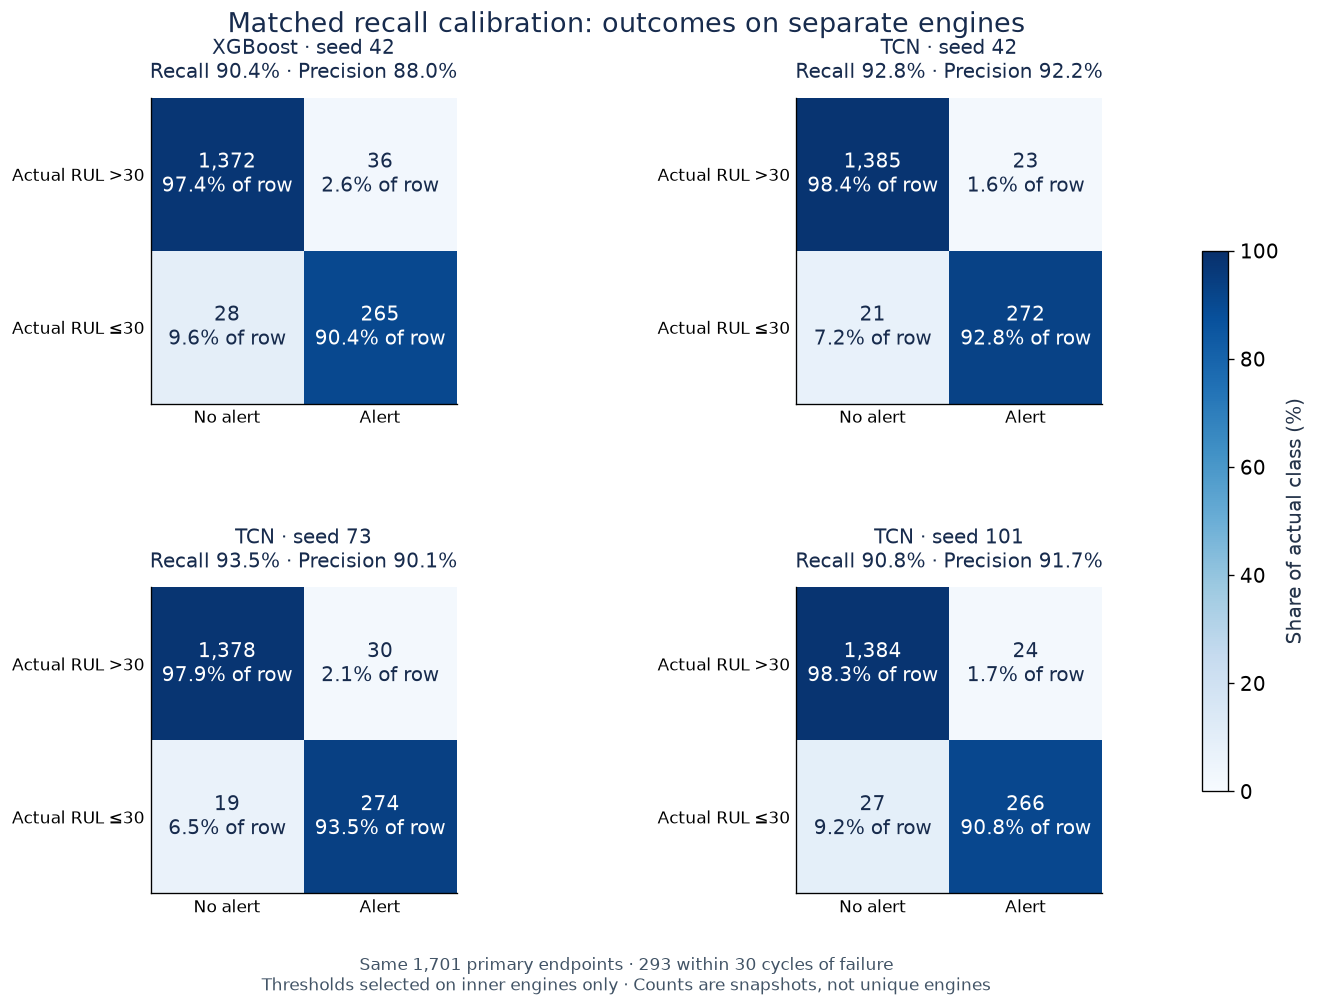

In [17]:
alerts=pd.read_csv(ROOT/'outputs/alert_comparison/metrics.csv')
calibrated=alerts[alerts.protocol.eq('primary') & alerts.rule.eq('inner_calibrated')]
model_order=[('XGBoost',42),('TCN',42),('TCN',73),('TCN',101)]
fig,axes=plt.subplots(2,2,figsize=(12,8.5))
for ax,(family,seed) in zip(axes.ravel(),model_order):
    result=calibrated[calibrated.model.eq(family) & calibrated.seed.eq(seed)].iloc[0]
    counts=np.array([[result.TN,result.FP],[result.FN,result.TP]],dtype=int)
    percentages=100*counts/counts.sum(axis=1,keepdims=True)
    im=ax.imshow(percentages,cmap='Blues',vmin=0,vmax=100)
    for row in range(2):
        for col in range(2):
            ax.text(col,row,f'{counts[row,col]:,}\n{percentages[row,col]:.1f}% of row',
                    ha='center',va='center',fontsize=12,
                    color='white' if percentages[row,col]>55 else '#172b4d')
    ax.set(xticks=[0,1],xticklabels=['No alert','Alert'],yticks=[0,1],
           yticklabels=['Actual RUL >30','Actual RUL ≤30'])
    ax.set_title(f'{family} · seed {seed}\nRecall {result.recall:.1%} · Precision {result.precision:.1%}',fontsize=12,pad=12)
    ax.tick_params(length=0,labelsize=10)
fig.subplots_adjust(left=.14,right=.86,bottom=.12,top=.90,wspace=.65,hspace=.60)
cax=fig.add_axes([.90,.22,.018,.53])
fig.colorbar(im,cax=cax,label='Share of actual class (%)')
fig.suptitle('Matched recall calibration: outcomes on separate engines',fontsize=16,y=.985)
fig.text(.5,.025,'Same 1,701 primary endpoints · 293 within 30 cycles of failure\n'
         'Thresholds selected on inner engines only · Counts are snapshots, not unique engines',
         ha='center',fontsize=10,color='#425466')
fig.savefig(OUT/'matched_alert_confusion.png',dpi=160,bbox_inches='tight')
plt.show()


XGBoost catches **265/293**, with **36 false alerts**. TCN catches **266–274**, with **23–30 false alerts**.

All three paired recall intervals include zero: the observed tradeoff favors TCN, but a recall advantage is unproven. No seed is selected from these outcomes. [Methods and uncertainty](outputs/alert_comparison/METHODS.md).


### Overfitting: measurable gaps in both models

Same uncapped endpoints for fitting and held-out engines. Errors pool three folds; each fitting engine appears twice, each validation engine once. Gaps are descriptive, not confidence intervals.


In [18]:
gaps=pd.read_csv(ROOT/'outputs/tcn_followup/generalization_summary.csv')
xgb_gaps=pd.read_csv(EXP/'generalization_summary.csv')
xgb=xgb_gaps[xgb_gaps.protocol.eq('primary') & xgb_gaps.subset.eq('all')].iloc[0]
rows=[{'Model / seed':'XGBoost / 42','Training RMSE':xgb.training_RMSE,
       'Validation RMSE':xgb.validation_RMSE,'Gap':xgb.gap}]
for row in gaps[gaps.window.eq(50) & gaps.protocol.eq('primary') & gaps.subset.eq('all')].itertuples():
    rows.append({'Model / seed':f'TCN 50 / {row.seed}','Training RMSE':row.training_RMSE,
                 'Validation RMSE':row.validation_RMSE,'Gap':row.gap})
display(pd.DataFrame(rows).set_index('Model / seed').rename_axis(index=None).round(2))


,Training RMSE,Validation RMSE,Gap
XGBoost / 42,17.79,25.93,8.14
TCN 50 / 42,19.13,23.69,4.56
TCN 50 / 73,19.68,23.59,3.91
TCN 50 / 101,18.66,24.13,5.46


Primary training–validation gap: **XGBoost 8.14**, **TCN 3.91–5.46 cycles**. TCN lowers overall CV error; XGBoost lowers near-failure error: **7.51 vs 8.22–9.51**.

Leakage and prediction-reproduction checks pass, but repeated development selection remains a risk. [XGBoost](outputs/experiments/METHODS.md) / [TCN diagnostics](outputs/tcn_followup/METHODS.md).


### Does reducing the gap improve prediction?

XGBoost's inner-selected regularization scores **26.06 vs 25.93** primary RMSE. A shallower model reduces the gap but worsens RMSE to 26.75.

A smaller TCN reduces gaps but worsens RMSE in two of three seeds and near-failure error in all three. Inner validation retains the original TCN in all nine runs.

**Keep the existing recipes.** Smaller fitting gaps alone do not imply better prediction. [Results](outputs/regularization/METHODS.md).


## 13. Full training: all engines, all test endpoints

Train three 50-cycle TCNs on **709 engines / 160,359 cycles** for **25/27/30 epochs**, chosen from prior inner CV. Equal ensemble weights were declared before scoring.

Final thresholds use pooled development OOF calibration, unlike the inner-fold calibration above. Test: **159 positive / 548 negative engines**, uncapped labels. Previously examined benchmark; the old audit engines now belong to full training.


In [19]:
full_metrics=pd.read_csv(ROOT/'outputs/tcn_full/test_metrics.csv')
full_names={'XGBoost':'XGBoost','TCN_seed42':'TCN seed 42','TCN_seed73':'TCN seed 73',
            'TCN_seed101':'TCN seed 101','TCN_ensemble':'TCN equal-weight ensemble'}
full=full_metrics[full_metrics.dataset.eq('ALL') & full_metrics.rule.eq('development_calibrated')].copy()
full['Model']=full.model.map(full_names)
shown=full[['Model','RMSE','near_failure_RMSE','threshold','recall','precision','FN','FP']].copy()
shown.columns=['Model','RMSE (cycles)','RMSE at RUL ≤30','Alert threshold','Recall','Precision','Missed','False alerts']
shown['Recall']=shown['Recall'].map(lambda x:f'{x:.1%}')
shown['Precision']=shown['Precision'].map(lambda x:f'{x:.1%}')
display(shown.set_index('Model').rename_axis(None).round(2))


,RMSE (cycles),RMSE at RUL ≤30,Alert threshold,Recall,Precision,Missed,False alerts
XGBoost,22.63,6.50,34.44,93.7%,92.5%,10,12
TCN seed 42,20.30,5.63,34.57,98.7%,95.2%,2,8
TCN seed 73,20.45,8.99,34.82,95.6%,94.4%,7,9
TCN seed 101,21.32,10.14,35.45,91.8%,97.3%,13,4
TCN equal-weight ensemble,20.09,7.88,34.27,94.3%,96.2%,9,6


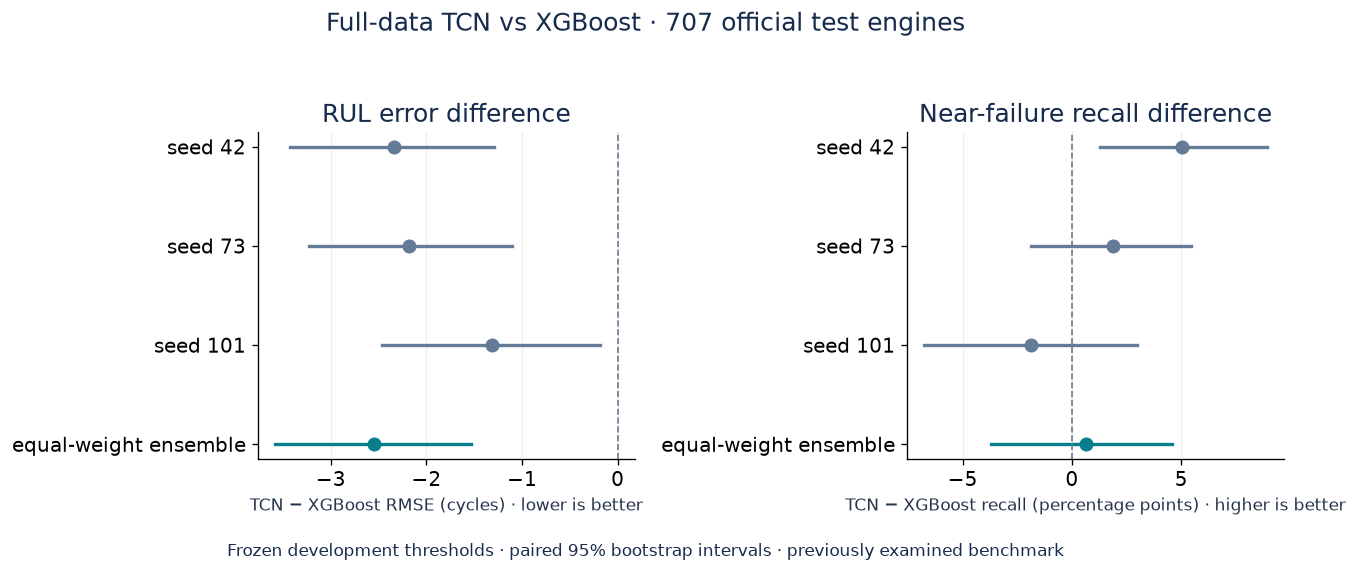

In [20]:
full_pairs=pd.read_csv(ROOT/'outputs/tcn_full/paired_comparisons.csv')
cal_pairs=full_pairs[full_pairs.rule.eq('development_calibrated')]
fig,axes=plt.subplots(1,2,figsize=(11,4.7))
variants=['TCN_seed42','TCN_seed73','TCN_seed101','TCN_ensemble']
for ax,metric,scale,title,label in zip(axes,['RMSE','recall'],[1,100],
        ['RUL error difference','Near-failure recall difference'],
        ['TCN − XGBoost RMSE (cycles) · lower is better',
         'TCN − XGBoost recall (percentage points) · higher is better']):
    rows=cal_pairs[cal_pairs.metric.eq(metric)].set_index('model').loc[variants]
    for j,(name,row) in enumerate(rows.iterrows()):
        color='#087f8c' if name=='TCN_ensemble' else '#637b96'
        ax.plot([row.lower95*scale,row.upper95*scale],[j,j],color=color,lw=2)
        ax.scatter(row.difference*scale,j,color=color,s=55,zorder=3)
    ax.axvline(0,color='#637b96',lw=1,ls='--')
    ax.set_yticks(range(4),[full_names[v].replace('TCN ','') for v in variants])
    ax.invert_yaxis();ax.set_xlabel(label,fontsize=10);ax.set_title(title)
    ax.grid(axis='x',alpha=.2)
fig.suptitle('Full-data TCN vs XGBoost · 707 official test engines',fontsize=15)
fig.text(.5,.015,'Frozen development thresholds · paired 95% bootstrap intervals · previously examined benchmark',
         ha='center',fontsize=10)
fig.tight_layout(rect=[0,.05,1,.94])
fig.savefig(OUT/'full_tcn_comparison.png',dpi=150,bbox_inches='tight')
plt.show()


**Ensemble RMSE: 20.09 vs 22.63 (−11.2%)**; improvement 95% interval **1.54–3.59 cycles**. All four subsets improve.

Calibrated alerts catch **150/159 vs 149/159**, with **6 vs 12 false alerts**. Recall difference: **+0.63 percentage points [−3.68, +4.58]**—not conclusive. Individual-seed recall spans 91.8–98.7%; choosing the best test seed would add selection bias.

**Tradeoffs:** fixed-30 ensemble recall is **83.0% vs 89.9%**; near-failure RMSE is **7.88 vs 6.50**. Seed 42's NASA score worsens; the ensemble's improves.

Paired, dataset-stratified intervals condition on fitted models/thresholds and exclude selection uncertainty and multiplicity correction. [Methods](outputs/tcn_full/METHODS.md) · [All subsets/policies](outputs/tcn_full/test_metrics.csv) · [Intervals](outputs/tcn_full/paired_comparisons.csv).


## 14. Conclusion

TCN improves overall prediction error and reduces observed false alerts. Its recall advantage remains uncertain. Validation on new data is needed before operational use.


See the [README](README.md) for supporting experiments, methods and reproduction instructions.
